# Bank Financial Ratio Analysis

**Business question:** which big US banks earn their returns by running the business well, and which get them by borrowing more?

**Why it matters:** banks are usually compared on one number, ROE (return on equity). But a bank can raise its ROE in two ways: earn more profit from what it owns, or borrow more. The second way adds risk. An investor or a credit analyst needs to know which one they are looking at.

**Data:** annual reports (10-K filings) of 13 large US banks for 2016 to 2025, pulled from the SEC's public data service.

**This notebook has four parts:**

- **Part 1: Pull the data** from the SEC and save it as a table.

- **Part 2: Load it into SQL** (DuckDB) as two tables.

- **Part 3: Analysis in SQL:** ratios, year-over-year change, rankings, and the split of ROE into its two parts.

- **Part 4: Charts and conclusion.**

**How to read the numbers:**

- **ROE (return on equity)** = profit divided by shareholders' money. How much the owners earn on what they put in.

- **ROA (return on assets)** = profit divided by everything the bank owns. How well the bank uses its assets. This is the "running the business well" part.

- **Leverage** = assets divided by shareholders' money. A leverage of 12 means the bank holds 12 dollars of assets for every 1 dollar of its own money. The rest is deposits and borrowing.

- **ROE = ROA x Leverage.** This is the key idea of the project. It is a standard method called DuPont analysis.

- **Efficiency ratio** = costs divided by revenue. What the bank spends to earn 1 dollar. Lower is better.

- **NIM (net interest margin)** = net interest income divided by assets. What the bank earns from lending. It is simplified here: banks normally divide by interest-earning assets only.

---

# Part 1: Pull the Data from the SEC

Every public company reports its numbers to the SEC with standard tags, for example `NetIncomeLoss` for profit. The SEC serves these as one file per company.

The SEC asks every program to say who is calling. Put your own name and email in the line below before running.

In [1]:
import requests
import pandas as pd

headers = {"User-Agent": "Your Name your.email@example.com"}

# The 13 banks and their SEC company numbers (CIK)
banks = {
    "JPM": 19617,
    "BAC": 70858,
    "WFC": 72971,
    "C": 831001,
    "GS": 886982,
    "MS": 895421,
    "PNC": 713676,
    "KEY": 91576,
    "CFG": 759944,
    "COF": 927628,
    "AXP": 4962,
    "SCHW": 316709,
    "STT": 93751,
}

<br>

Banks do not all use the same tag for the same number. For revenue, some report `Revenues` and others `RevenuesNetOfInterestExpense`. For profit, most report `NetIncomeLoss` and one (PNC) reports `ProfitLoss`. So for each number there is a short list of tags to try, in order.

<br>

In [2]:
# For each number we need: the tags to try, and whether it is a balance sheet number.
# Income statement numbers cover a full year. Balance sheet numbers are a snapshot on December 31.
items = {
    "net_income": (["NetIncomeLoss", "ProfitLoss"], False),
    "net_interest_income": (["InterestIncomeExpenseNet"], False),
    "revenue": (["Revenues", "RevenuesNetOfInterestExpense"], False),
    "noninterest_expense": (["NoninterestExpense"], False),
    "total_assets": (["Assets"], True),
    "total_equity": (["StockholdersEquity"], True),
}

years = [2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]

In [3]:
rows = []

for ticker, cik in banks.items():
    url = f"https://data.sec.gov/api/xbrl/companyfacts/CIK{cik:010d}.json"
    facts = requests.get(url, headers=headers).json()["facts"]["us-gaap"]

    for item, (tags, is_balance_sheet) in items.items():
        for year in years:
            value = None

            for tag in tags:
                if tag not in facts:
                    continue

                for fact in facts[tag]["units"]["USD"]:
                    # Keep only numbers from annual reports, for the year ending December 31
                    if fact["form"] != "10-K" or fact["end"] != f"{year}-12-31":
                        continue
                    # Income statement numbers must cover the full year, not one quarter
                    if not is_balance_sheet and fact.get("start") != f"{year}-01-01":
                        continue
                    value = fact["val"]

                if value is not None:
                    break

            rows.append({"ticker": ticker, "year": year, "item": item, "value_usd": value})

    print(ticker, "pulled")

financials = pd.DataFrame(rows)
print(financials.shape)

JPM pulled


BAC pulled


WFC pulled


C pulled


GS pulled


MS pulled


... (3 outputs left out)

COF pulled


AXP pulled


SCHW pulled


STT pulled
(780, 4)


<br>

**Check:** 13 banks x 10 years x 6 numbers should give 780 rows, with nothing missing.

<br>

In [4]:
print("Rows:", len(financials))
print("Missing values:", financials["value_usd"].isna().sum())

financials.to_csv("bank_financials.csv", index=False)
financials.head(6)

Rows: 780
Missing values: 0


,ticker,year,item,value_usd
0,JPM,2016,net_income,24733000000
1,JPM,2017,net_income,24441000000
2,JPM,2018,net_income,32474000000
3,JPM,2019,net_income,36431000000
4,JPM,2020,net_income,29131000000
5,JPM,2021,net_income,48334000000


<br>

**Spot check against the filing:** JPMorgan's 2025 annual report shows net income of 57,048 million dollars and total assets of 4,424,900 million dollars.

<br>

In [5]:
jpm_2025 = financials[(financials["ticker"] == "JPM") & (financials["year"] == 2025)].copy()
jpm_2025["value_millions"] = jpm_2025["value_usd"] / 1e6
jpm_2025[["item", "value_millions"]]

,item,value_millions
9,net_income,57048.0
19,net_interest_income,95443.0
29,revenue,182447.0
39,noninterest_expense,95640.0
49,total_assets,4424900.0
59,total_equity,362438.0


---

# Part 2: Load the Data into SQL

Two tables:

- **financials:** one row per bank, year and number (the table saved above).

- **banks:** one row per bank, with its name and type. The type matters because a card lender, a regional bank and an investment bank work differently.

In [6]:
import duckdb

con = duckdb.connect()

con.sql("CREATE TABLE financials AS SELECT * FROM 'bank_financials.csv'")

con.sql("""
CREATE TABLE banks (ticker VARCHAR, bank_name VARCHAR, bank_type VARCHAR);

INSERT INTO banks VALUES
    ('JPM', 'JPMorgan Chase', 'Universal bank'),
    ('BAC', 'Bank of America', 'Universal bank'),
    ('WFC', 'Wells Fargo', 'Universal bank'),
    ('C', 'Citigroup', 'Universal bank'),
    ('GS', 'Goldman Sachs', 'Investment bank'),
    ('MS', 'Morgan Stanley', 'Investment bank'),
    ('PNC', 'PNC', 'Regional bank'),
    ('KEY', 'KeyCorp', 'Regional bank'),
    ('CFG', 'Citizens', 'Regional bank'),
    ('COF', 'Capital One', 'Card lender'),
    ('AXP', 'American Express', 'Card lender'),
    ('SCHW', 'Charles Schwab', 'Brokerage and custody'),
    ('STT', 'State Street', 'Brokerage and custody');
""")

con.sql("SELECT * FROM banks").df()

,ticker,bank_name,bank_type
0,JPM,JPMorgan Chase,Universal bank
1,BAC,Bank of America,Universal bank
2,WFC,Wells Fargo,Universal bank
3,C,Citigroup,Universal bank
4,GS,Goldman Sachs,Investment bank
5,MS,Morgan Stanley,Investment bank
6,PNC,PNC,Regional bank
7,KEY,KeyCorp,Regional bank
8,CFG,Citizens,Regional bank
9,COF,Capital One,Card lender


<br>

## Query 1: One Row per Bank and Year

The financials table is "long": one number per row. This query turns it into one row per bank and year, with a column for each number, and joins the bank's name and type. `CASE WHEN` picks each number out, and `JOIN` adds the bank details.

<br>

In [7]:
con.sql("""
CREATE VIEW bank_year AS
SELECT
    b.ticker,
    b.bank_name,
    b.bank_type,
    f.year,
    SUM(CASE WHEN f.item = 'net_income' THEN f.value_usd END) AS net_income,
    SUM(CASE WHEN f.item = 'net_interest_income' THEN f.value_usd END) AS net_interest_income,
    SUM(CASE WHEN f.item = 'revenue' THEN f.value_usd END) AS revenue,
    SUM(CASE WHEN f.item = 'noninterest_expense' THEN f.value_usd END) AS noninterest_expense,
    SUM(CASE WHEN f.item = 'total_assets' THEN f.value_usd END) AS total_assets,
    SUM(CASE WHEN f.item = 'total_equity' THEN f.value_usd END) AS total_equity
FROM financials AS f
JOIN banks AS b
    ON f.ticker = b.ticker
GROUP BY b.ticker, b.bank_name, b.bank_type, f.year
""")

con.sql("SELECT * FROM bank_year WHERE year = 2025 ORDER BY total_assets DESC").df()

,ticker,bank_name,bank_type,year,net_income,net_interest_income,revenue,noninterest_expense,total_assets,total_equity
0,JPM,JPMorgan Chase,Universal bank,2025,5.704800e+10,9.544300e+10,1.824470e+11,9.564000e+10,4.424900e+12,3.624380e+11
1,BAC,Bank of America,Universal bank,2025,3.050900e+10,6.009600e+10,1.130970e+11,6.972700e+10,3.411738e+12,3.032430e+11
2,C,Citigroup,Universal bank,2025,1.430600e+10,5.979200e+10,8.522500e+10,5.513200e+10,2.657202e+12,2.122910e+11
3,WFC,Wells Fargo,Universal bank,2025,2.133800e+10,4.748400e+10,8.369900e+10,5.484200e+10,2.148631e+12,1.811170e+11
4,GS,Goldman Sachs,Investment bank,2025,1.717600e+10,1.355900e+10,5.828300e+10,3.754400e+10,1.809320e+12,1.249720e+11
5,MS,Morgan Stanley,Investment bank,2025,1.686100e+10,1.004600e+10,7.064500e+10,4.834200e+10,1.420270e+12,1.116320e+11
6,COF,Capital One,Card lender,2025,2.453000e+09,4.287800e+10,5.343400e+10,3.049800e+10,6.690090e+11,1.136160e+11
7,PNC,PNC,Regional bank,2025,6.997000e+09,1.441000e+10,2.309900e+10,1.383400e+10,5.735720e+11,6.058500e+10
8,SCHW,Charles Schwab,Brokerage and custody,2025,8.852000e+09,1.175000e+10,2.392100e+10,1.246200e+10,4.909950e+11,4.942500e+10
9,STT,State Street,Brokerage and custody,2025,2.945000e+09,2.960000e+09,1.394400e+10,1.015400e+10,3.660470e+11,2.784100e+10


---

# Part 3: Analysis in SQL

## Query 2: The Five Ratios

In [8]:
con.sql("""
CREATE VIEW ratios AS
SELECT
    ticker,
    bank_name,
    bank_type,
    year,
    ROUND(net_income / total_equity * 100, 2) AS roe_pct,
    ROUND(net_income / total_assets * 100, 2) AS roa_pct,
    ROUND(total_assets / total_equity, 2) AS leverage,
    ROUND(noninterest_expense / revenue * 100, 1) AS efficiency_pct,
    ROUND(net_interest_income / total_assets * 100, 2) AS nim_pct
FROM bank_year
""")

con.sql("SELECT * FROM ratios WHERE year = 2025 ORDER BY roe_pct DESC").df()

,ticker,bank_name,bank_type,year,roe_pct,roa_pct,leverage,efficiency_pct,nim_pct
0,AXP,American Express,Card lender,2025,32.36,3.61,8.96,73.6,5.79
1,SCHW,Charles Schwab,Brokerage and custody,2025,17.91,1.80,9.93,52.1,2.39
2,JPM,JPMorgan Chase,Universal bank,2025,15.74,1.29,12.21,52.4,2.16
3,MS,Morgan Stanley,Investment bank,2025,15.10,1.19,12.72,68.4,0.71
4,GS,Goldman Sachs,Investment bank,2025,13.74,0.95,14.48,64.4,0.75
5,WFC,Wells Fargo,Universal bank,2025,11.78,0.99,11.86,65.5,2.21
6,PNC,PNC,Regional bank,2025,11.55,1.22,9.47,59.9,2.51
7,STT,State Street,Brokerage and custody,2025,10.58,0.80,13.15,72.8,0.81
8,BAC,Bank of America,Universal bank,2025,10.06,0.89,11.25,61.7,1.76
9,KEY,KeyCorp,Regional bank,2025,8.97,0.99,9.05,62.6,2.51


<br>

**Check that ROE = ROA x Leverage** holds in the data. The two columns should match, apart from rounding.

<br>

In [9]:
con.sql("""
SELECT
    ticker,
    year,
    roe_pct,
    ROUND(roa_pct * leverage, 2) AS roa_times_leverage
FROM ratios
WHERE year = 2025
ORDER BY ticker
""").df()

,ticker,year,roe_pct,roa_times_leverage
0,AXP,2025,32.36,32.35
1,BAC,2025,10.06,10.01
2,C,2025,6.74,6.76
3,CFG,2025,6.96,6.97
4,COF,2025,2.16,2.18
5,GS,2025,13.74,13.76
6,JPM,2025,15.74,15.75
7,KEY,2025,8.97,8.96
8,MS,2025,15.10,15.14
9,PNC,2025,11.55,11.55


<br>

## Query 3: ROE Rank in Each Year

`RANK() OVER (PARTITION BY year ...)` ranks the banks separately inside each year.

<br>

In [10]:
roe_rank = con.sql("""
SELECT
    year,
    ticker,
    roe_pct,
    RANK() OVER (PARTITION BY year ORDER BY roe_pct DESC) AS roe_rank
FROM ratios
ORDER BY year, roe_rank
""").df()

# Show it as one row per bank and one column per year
roe_rank.pivot(index="ticker", columns="year", values="roe_rank")

year,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
ticker,,,,,,,,,,
AXP,1,1,1,1,2,1,1,1,1,1
BAC,10,10,10,7,8,7,9,7,9,9
C,11,13,12,9,10,9,13,13,12,12
CFG,12,8,13,13,11,12,11,11,11,11
COF,8,12,5,10,12,2,4,8,10,13
GS,7,11,6,11,5,3,10,10,5,5
JPM,5,6,3,3,4,4,6,2,2,3
KEY,13,7,4,8,7,5,3,11,13,10
MS,9,9,9,4,3,6,7,6,3,4


<br>

## Query 4: Change in ROE from the Year Before

`LAG()` looks up the same bank's ROE one year earlier, so the change can be calculated in one query.

<br>

In [11]:
con.sql("""
SELECT
    ticker,
    year,
    roe_pct,
    LAG(roe_pct) OVER (PARTITION BY ticker ORDER BY year) AS roe_last_year,
    ROUND(roe_pct - LAG(roe_pct) OVER (PARTITION BY ticker ORDER BY year), 2) AS change_in_points
FROM ratios
WHERE ticker IN ('JPM', 'GS', 'COF')
ORDER BY ticker, year
""").df()

,ticker,year,roe_pct,roe_last_year,change_in_points
0,COF,2016,7.89,NaN,NaN
1,COF,2017,4.07,7.89,-3.82
2,COF,2018,11.64,4.07,7.57
3,COF,2019,9.56,11.64,-2.08
4,COF,2020,4.51,9.56,-5.05
5,COF,2021,20.30,4.51,15.79
6,COF,2022,14.00,20.30,-6.30
7,COF,2023,8.41,14.00,-5.59
8,COF,2024,7.81,8.41,-0.60
9,COF,2025,2.16,7.81,-5.65


<br>

## Query 5: Where Does Each Bank's ROE Come From?

This is the main query. It answers the business question in three steps, each one a named block (`WITH ...`):

1. **five_year:** each bank's average ROE, ROA and leverage over 2016 to 2025.

2. **typical:** the leverage of the middle bank of the group (the median).

3. **Final step:** what each bank's ROE would be if it used that typical leverage. That is its ROA x the typical leverage. The gap between the real ROE and this number is the part that comes from borrowing more (or less) than the others. The last two columns rank the banks both ways.

<br>

In [12]:
dupont = con.sql("""
WITH five_year AS (
    SELECT
        ticker,
        bank_name,
        bank_type,
        ROUND(AVG(roe_pct), 2) AS roe_pct,
        ROUND(AVG(roa_pct), 2) AS roa_pct,
        ROUND(AVG(leverage), 2) AS leverage
    FROM ratios
    GROUP BY ticker, bank_name, bank_type
),
typical AS (
    SELECT MEDIAN(leverage) AS typical_leverage
    FROM five_year
)
SELECT
    f.bank_name,
    f.bank_type,
    f.roe_pct,
    f.roa_pct,
    f.leverage,
    ROUND(f.roa_pct * t.typical_leverage, 2) AS roe_at_typical_leverage,
    ROUND(f.roe_pct - f.roa_pct * t.typical_leverage, 2) AS points_from_leverage,
    RANK() OVER (ORDER BY f.roe_pct DESC) AS rank_by_roe,
    RANK() OVER (ORDER BY f.roa_pct * t.typical_leverage DESC) AS rank_at_typical_leverage
FROM five_year AS f
CROSS JOIN typical AS t
ORDER BY f.roe_pct DESC
""").df()

dupont

,bank_name,bank_type,roe_pct,roa_pct,leverage,roe_at_typical_leverage,points_from_leverage,rank_by_roe,rank_at_typical_leverage
0,American Express,Card lender,27.77,3.17,8.80,32.81,-5.04,1,1
1,Charles Schwab,Brokerage and custody,13.67,1.11,12.32,11.49,2.18,2,5
2,JPMorgan Chase,Universal bank,13.34,1.18,11.32,12.21,1.13,3,4
3,PNC,Regional bank,11.34,1.23,9.39,12.73,-1.39,4,2
4,Morgan Stanley,Investment bank,11.09,0.97,11.38,10.04,1.05,5,6
5,Goldman Sachs,Investment bank,10.66,0.87,12.24,9.00,1.66,6,10
6,State Street,Brokerage and custody,9.89,0.85,11.72,8.80,1.09,7,12
7,Wells Fargo,Universal bank,9.80,0.95,10.35,9.83,-0.03,8,7
8,Bank of America,Universal bank,9.13,0.90,10.14,9.31,-0.18,9,8
9,Capital One,Card lender,9.04,1.21,7.39,12.52,-3.48,10,3


<br>

## Query 6: What Drives ROA? Costs and Lending Margin by Bank Type

<br>

In [13]:
con.sql("""
SELECT
    bank_type,
    COUNT(DISTINCT ticker) AS banks,
    ROUND(AVG(roa_pct), 2) AS avg_roa_pct,
    ROUND(AVG(efficiency_pct), 1) AS avg_efficiency_pct,
    ROUND(AVG(nim_pct), 2) AS avg_nim_pct,
    ROUND(AVG(leverage), 1) AS avg_leverage
FROM ratios
GROUP BY bank_type
ORDER BY avg_roa_pct DESC
""").df()

,bank_type,banks,avg_roa_pct,avg_efficiency_pct,avg_nim_pct,avg_leverage
0,Card lender,2,2.19,64.1,5.24,8.1
1,Regional bank,3,0.99,64.4,2.46,9.3
2,Brokerage and custody,2,0.98,66.7,1.33,12.0
3,Investment bank,2,0.92,68.3,0.52,11.8
4,Universal bank,4,0.91,62.7,2.09,10.6


In [14]:
con.sql("SELECT * FROM ratios ORDER BY ticker, year").df().to_csv("bank_ratios.csv", index=False)
dupont.to_csv("roe_breakdown.csv", index=False)
print("Saved bank_ratios.csv and roe_breakdown.csv")

Saved bank_ratios.csv and roe_breakdown.csv


---

# Part 4: Charts and Conclusion

## Chart 1: Real ROE and ROE at the Same Leverage

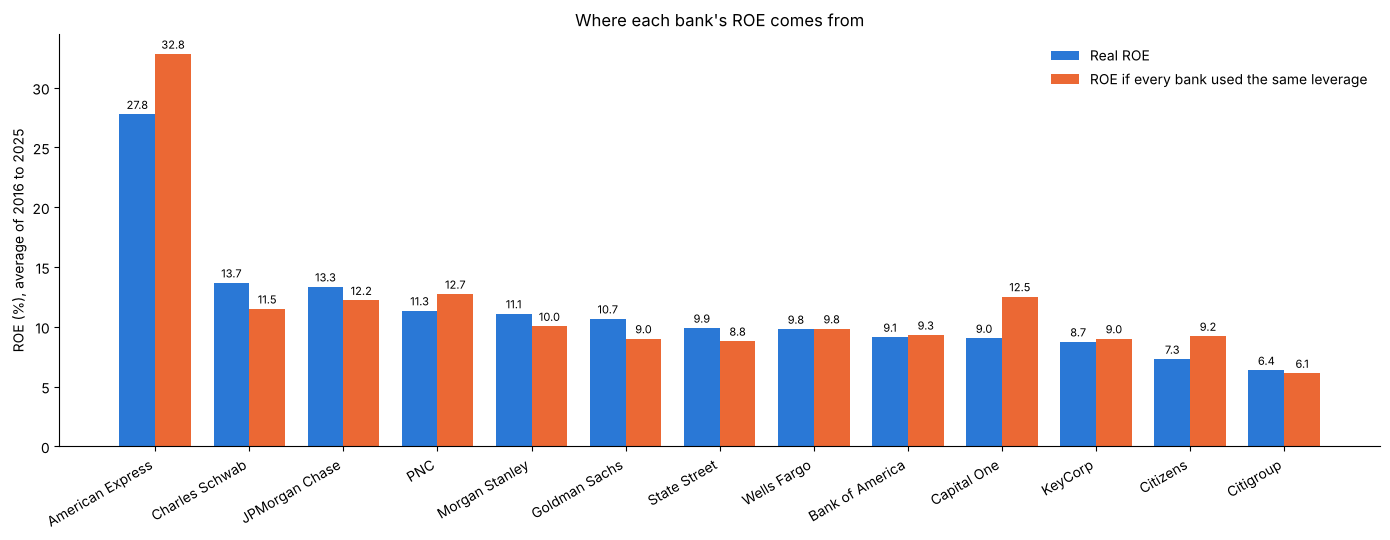

In [15]:
import matplotlib.pyplot as plt
import numpy as np

names = dupont["bank_name"]
x = np.arange(len(names))
width = 0.38

fig, ax = plt.subplots(figsize=(14, 5.5))

bars_1 = ax.bar(x - width / 2, dupont["roe_pct"], width, label="Real ROE", color="#2a78d6")
bars_2 = ax.bar(
    x + width / 2,
    dupont["roe_at_typical_leverage"],
    width,
    label="ROE if every bank used the same leverage",
    color="#eb6834",
)

ax.bar_label(bars_1, fmt="%.1f", padding=2, fontsize=8)
ax.bar_label(bars_2, fmt="%.1f", padding=2, fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(names, rotation=30, ha="right")
ax.set_ylabel("ROE (%), average of 2016 to 2025")
ax.set_title("Where each bank's ROE comes from")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)

plt.tight_layout()
plt.savefig("roe_breakdown.png", dpi=150)
plt.show()

<br>

## Chart 2: ROE of Each Bank over Time

<br>

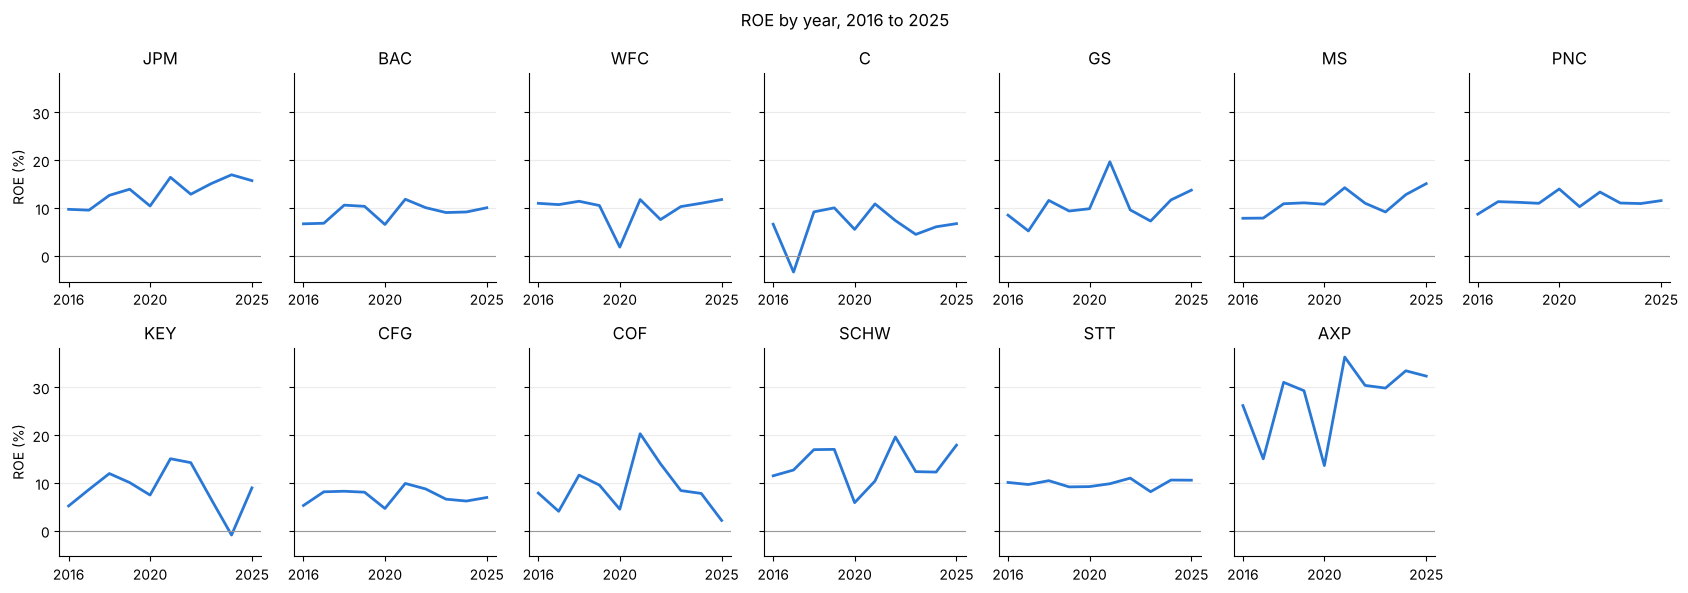

In [16]:
roe_by_year = con.sql("SELECT ticker, year, roe_pct FROM ratios ORDER BY ticker, year").df()

# American Express is far above the others, so it is listed last and the y-axis is shared
tickers = ["JPM", "BAC", "WFC", "C", "GS", "MS", "PNC", "KEY", "CFG", "COF", "SCHW", "STT", "AXP"]

fig, axes = plt.subplots(2, 7, figsize=(17, 6), sharey=True)
axes = axes.flatten()

for ax, ticker in zip(axes, tickers):
    one = roe_by_year[roe_by_year["ticker"] == ticker]
    ax.plot(one["year"], one["roe_pct"], color="#2a78d6", linewidth=2)
    ax.axhline(0, color="#999999", linewidth=0.8)
    ax.set_title(ticker)
    ax.set_xticks([2016, 2020, 2025])
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.25)

axes[13].axis("off")
axes[0].set_ylabel("ROE (%)")
axes[7].set_ylabel("ROE (%)")
fig.suptitle("ROE by year, 2016 to 2025")

plt.tight_layout()
plt.savefig("roe_by_year.png", dpi=150)
plt.show()

<br>

## Conclusion

**The question:** which banks earn their returns by running the business well, and which by borrowing more?

To answer it, each bank's ROE was recalculated as if every bank used the same leverage (the typical bank's 10.35). The ranking changes a lot.

**1. Capital One looks much worse than it is.** It ranks 10th of 13 on ROE (9.0%), but 3rd once leverage is made equal. It earns more on its assets than almost any other bank (ROA 1.21%) and borrows the least (leverage 7.4).

**2. The three banks that borrow the most all drop.** Charles Schwab falls from 2nd to 5th, Goldman Sachs from 6th to 10th, and State Street from 7th to 12th. Their ROE is lifted by leverage of about 12.

**3. JPMorgan's ROE is mostly earned.** It moves only from 3rd to 4th.

**4. American Express is first either way.** Its ROE (27.8%) and ROA (3.17%) are far above every other bank. It earns fees on card spending, which needs few assets, so it is a different kind of business and not a fair yardstick for the others.

**5. Citigroup is last either way** (ROE 6.4%, ROA 0.59%). Its leverage is typical, so the weakness is in the business itself.

**6. Bank types work differently.** Card lenders earn 5.2% on lending (NIM), regional banks 2.5%, universal banks 2.1%, and investment banks 0.5%. NIM should only be compared between banks of the same type.

**What this means:** ranking banks by ROE alone would put Goldman Sachs four places above Capital One. With leverage made equal, Capital One is seven places above Goldman Sachs.

**Limits of this analysis:**

- Ratios use year-end balance sheet numbers, not averages over the year.

- NIM is simplified (divided by total assets).

- Higher leverage does not mean the same risk at every bank. Charles Schwab and State Street mostly hold client cash in safe assets. A card lender takes more credit risk, so it has to hold more of its own money.

- PNC reports profit under a slightly different tag (`ProfitLoss`), which includes a small share belonging to outside partners.

- 2025 was unusual for Capital One: it bought Discover that year, which roughly doubled its equity and pulled its ROE down to 2.2%.

- Leverage here is a simple accounting measure. Regulators use risk-weighted capital ratios such as CET1, which are not in these data.

<br>